In [90]:
import numpy as np
from tqdm import tqdm
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

In [3]:
# [[18, 4, 4]]
l,m = 3, 3
a1,a2,a3 = 1, 0, 2
b1,b2,b3 = 1, 0, 2
n = 2*m*l;  n2 = m*l
I_l = np.identity(l, dtype=int) ; I_m = np.identity(m, dtype=int); I = np.identity(l*m, dtype=int)
x = {} ;  y = {}
for i in range(l):
	x[i] = np.kron(np.roll(I_l,i,axis=1),I_m)
for i in range(m):
	y[i] = np.kron(I_l,np.roll(I_m,i,axis=1))
A = (x[a1%l] + y[a2%m] + y[a3%m]) % 2
B = (y[b1%m] + x[b2%l] + x[b3%l]) % 2
A1 = x[a1%l]; A2 = y[a2%m]; A3 = y[a3%m]
B1 = y[b1%m]; B2 = x[b2%l]; B3 = x[b3%l]
AT = np.transpose(A) ; BT = np.transpose(B)
hx = np.hstack((A,B));  hz = np.hstack((BT,AT))


In [4]:
stabs = hx[0:7]

In [5]:
# To generate all possible errors
fallthrougherrors = 0
fallthrougherrorweights = []
p = 0.1
fallthrougherrorprobs = 0
elist = []
for i in tqdm(range(1, 2**(18))):
    bit = np.array(list(np.binary_repr(i, width=18)), dtype=int)
    if np.sum(bit) != 6 and np.sum(bit) != 4 and np.sum(bit) != 8:
        #pass
        continue
    for row in stabs:
        if np.sum(bit*row) % 2 == 1:
            break
    else:
        fallthrougherrors += 1
        fallthrougherrorweights.append(np.sum(bit))
        fallthrougherrorprobs += p**np.sum(bit)
        elist.append(bit)
print(fallthrougherrors, fallthrougherrorprobs)


100%|██████████| 262143/262143 [00:01<00:00, 150402.13it/s]

1023 0.004809749999999991


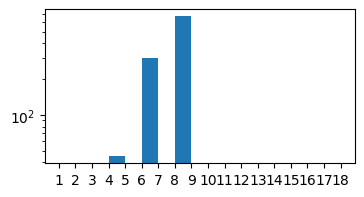

In [6]:
plt.figure(figsize = (4, 2))
plt.hist(fallthrougherrorweights, bins=range(1,19))
plt.xticks(range(1,19))
plt.yscale('log')
plt.show()

In [7]:
targetweight = 4
logicaloperators = []
for i in tqdm(range(2**18)):
    bit = np.array(list(np.binary_repr(i, width=18)), dtype=int)
    if np.sum(bit) == targetweight:
        for row in stabs:
            if np.sum(bit*row) % 2 == 1:
                break
            elif np.equal(bit, row).all():
                break
        else:
            logicaloperators.append(bit)
print(len(logicaloperators))

100%|██████████| 262144/262144 [00:00<00:00, 294146.96it/s]

45


In [8]:
stabssingle = np.zeros((8, 18))
stabssingle[0:7] = stabs.copy()
stabssingle[7] = logicaloperators[0]
print(stabssingle)

[[1. 0. 1. 1. 0. 0. 0. 0. 0. 1. 1. 0. 0. 0. 0. 1. 0. 0.]
 [1. 1. 0. 0. 1. 0. 0. 0. 0. 0. 1. 1. 0. 0. 0. 0. 1. 0.]
 [0. 1. 1. 0. 0. 1. 0. 0. 0. 1. 0. 1. 0. 0. 0. 0. 0. 1.]
 [0. 0. 0. 1. 0. 1. 1. 0. 0. 1. 0. 0. 1. 1. 0. 0. 0. 0.]
 [0. 0. 0. 1. 1. 0. 0. 1. 0. 0. 1. 0. 0. 1. 1. 0. 0. 0.]
 [0. 0. 0. 0. 1. 1. 0. 0. 1. 0. 0. 1. 1. 0. 1. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0. 1. 0. 1. 0. 0. 0. 1. 0. 0. 1. 1. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 1. 0. 0. 0. 0. 1. 1.]]


In [44]:
print(len(logicaloperators))

45


In [186]:
# Generate promotion pathways
promotions = [] # List of lists of promotion pathways
num = 100
for i in range(4):
    thispromotions = []
    if i == 0:
        thispromotions.append(stabs.copy())
        promotions.append(thispromotions)
        continue
    for n in range(num):
        thisstabs = np.zeros((7 + i, 18))
        thisstabs[0:7] = stabs.copy()
        newlogicals = np.random.choice(45, size = i, replace = False)
        for j in range(i):
            thisstabs[7 + j] = logicaloperators[newlogicals[j]]
        thispromotions.append(thisstabs)
    promotions.append(thispromotions)

errorlandscaperanked = np.logspace(-0.3, 0.3, 18)
errorlandscapehotspot = np.ones(18) * 0.9
errorlandscapehotspot[0] = 6
print(errorlandscapehotspot)
print(errorlandscaperanked)
def random_error_landscape(p, type = 'uniform'):
    if type == 'uniform':
        return np.ones(18) * p
    elif type == 'ranked':
        return np.random.permutation(errorlandscaperanked) * p
    elif type == 'hotspot':
        return np.random.permutation(errorlandscapehotspot) * p
print(random_error_landscape(0.1, 'ranked'), np.prod(random_error_landscape(1, 'ranked')))
print(random_error_landscape(0.1, 'hotspot'), np.prod(random_error_landscape(1, 'hotspot')))

def run_algebraic_enumeration(stabs, p, errorlandscape = random_error_landscape(p, 'uniform')):
    fallthrougherrorprobs = 0
    for i in range(1, 2**(18)):
        bit = np.array(list(np.binary_repr(i, width=18)), dtype=int)
        if np.sum(bit) != 6 and np.sum(bit) != 4 and np.sum(bit) != 8:
            #pass
            continue
        for row in stabs:
            if np.sum(bit*row) % 2 == 1:
                break
        else:
            fallthrougherrorprobs += np.prod(np.array(bit * errorlandscape)[np.where(bit * errorlandscape)])
    return fallthrougherrorprobs # LER

def linearfit(x, a, b):
    return a * x + b
def fitloglog(ers, lers):
    popt, _ = curve_fit(linearfit, np.log(ers), np.log(lers))
    return popt

[6.  0.9 0.9 0.9 0.9 0.9 0.9 0.9 0.9 0.9 0.9 0.9 0.9 0.9 0.9 0.9 0.9 0.9]
[0.50118723 0.54361836 0.58964176 0.63956156 0.69370763 0.75243777
 0.81614008 0.8852355  0.96018063 1.04147071 1.1296429  1.22527986
 1.32901356 1.44152948 1.56357114 1.695945   1.8395258  1.99526231]
[0.05436184 0.1695945  0.11296429 0.13290136 0.06937076 0.05011872
 0.06395616 0.15635711 0.18395258 0.10414707 0.08852355 0.08161401
 0.19952623 0.09601806 0.07524378 0.14415295 0.12252799 0.05896418] 1.0000000000000004
[0.09 0.09 0.09 0.09 0.09 0.09 0.09 0.09 0.09 0.09 0.09 0.09 0.09 0.09
 0.09 0.09 0.09 0.6 ] 1.0006309019799948


In [187]:
ers = [1e-2, 1e-3, 1e-4]
lers = [[[] for _ in range(len(ers))] for _ in range(4)] 
for i in range(4):
    for j in range(len(ers)):
        for k in tqdm(range(len(promotions[i]))):
            errorlandscape = random_error_landscape(ers[j], 'hotspot')
            #print(errorlandscape)
            lers[i][j].append(run_algebraic_enumeration(promotions[i][k], ers[j], errorlandscape = errorlandscape))

100%|██████████| 100/100 [02:44<00:00,  1.64s/it]


In [188]:
print(lers)

[[[np.float64(6.675002902579702e-07)], [np.float64(6.670396518904371e-11)], [np.float64(6.670350465188083e-15)]], [[np.float64(2.867308857104186e-07), np.float64(3.610828617366927e-07), np.float64(2.867308857104168e-07), np.float64(3.610828617366922e-07), np.float64(3.6108286173669256e-07), np.float64(2.8673088571041475e-07), np.float64(2.867308857104163e-07), np.float64(2.8673088571041665e-07), np.float64(3.6108286173669283e-07), np.float64(3.6108286173669283e-07), np.float64(2.8673088571041686e-07), np.float64(2.8673088571041787e-07), np.float64(3.610828617366921e-07), np.float64(2.8673088571041676e-07), np.float64(2.8673088571041776e-07), np.float64(2.867308857104159e-07), np.float64(2.86730885710418e-07), np.float64(2.867308857104168e-07), np.float64(2.867308857104167e-07), np.float64(3.6108286173669235e-07), np.float64(3.61082861736693e-07), np.float64(2.867308857104179e-07), np.float64(2.8673088571041824e-07), np.float64(2.8673088571041734e-07), np.float64(2.86730885710418e-07), 

In [171]:
print(np.mean(np.array(lers[1]), axis = 1))

[2.82839262e-07 2.79349265e-11 2.79563890e-15]


[4.0001514  4.20153806] 66.78897783318219
[4.00171236 3.4453437 ] 31.35405796985517
[3.99690864 2.68185473] 14.612169811277063
[4.00753368 1.95835009] 7.087623499349334


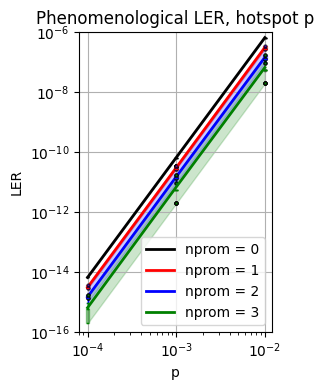

In [189]:
plt.figure(figsize=(3, 4))
#plt.plot(ers,np.mean(np.array(lers[0]), axis = 1), '-o', markersize = 2, label = 'nprom = 0', color = 'black')
#plt.plot(ers,np.mean(np.array(lers[1]), axis = 1), '-o', label = 'nprom = 1', color = 'red')
#plt.plot(ers,np.mean(np.array(lers[2]), axis = 1), '-o', label = 'nprom = 2', color = 'blue')
#plt.plot(ers,np.mean(np.array(lers[3]), axis = 1), '-o', label = 'nprom = 3', color = 'green')
colors = ['black', 'red', 'blue', 'green']
for color, i in zip(colors, range(0, 4)):
    vals, perc5, perc95 = [], [], []
    for j in range(len(ers)):
        vals = np.array(lers[i][j])
        perc5.append(np.percentile(vals, 5))
        perc95.append(np.percentile(vals, 95))
        # Box and whisker plot for each group/perror
        plt.boxplot(vals, positions=[ers[j]], widths=ers[j]*0.1, patch_artist=True,orientation = 'vertical',
                    boxprops=dict(facecolor=color, color=color, alpha=0.4),
                    medianprops=dict(color=color),
                    whiskerprops=dict(color=color),
                    capprops=dict(color=color),
                    flierprops=dict(markerfacecolor=color, marker='o', alpha=0.3, markersize=2, linestyle='none'))
    plt.plot(ers, np.mean(np.array(lers[i]), axis = 1), color=color, linewidth=2, label=f'nprom = {i}')
    plt.fill_between(ers, perc5, perc95, color=color, alpha=0.2)
plt.legend(loc = 'lower right')
popt = fitloglog(ers, np.mean(np.array(lers[0]), axis = 1))
popt2 = fitloglog(ers, np.mean(np.array(lers[1]), axis = 1))
popt3 = fitloglog(ers, np.mean(np.array(lers[2]), axis = 1))
popt4 = fitloglog(ers, np.mean(np.array(lers[3]), axis = 1))
print(popt, np.exp(popt[1]))
print(popt2, np.exp(popt2[1]))
print(popt3, np.exp(popt3[1]))
print(popt4, np.exp(popt4[1]))
plt.xlim(1e-4 *0.8, 1e-2 * 1.2)
plt.ylim(1e-16, 1e-6)
plt.yscale('log')
plt.xscale('log')
plt.xlabel('p')
plt.ylabel('LER')
title = 'Phenomenological LER, hotspot p'
plt.title(title)
plt.grid()
plt.tight_layout()
plt.savefig('manualimgs/' + title + '.png', dpi = 300)
plt.show()


In [10]:
# Run algebraic enumeration of error space
p = 0.1
nfallthrougherrors = 0
fallthrougherrorweights = []
fallthrougherrorprobs = 0
thisstabs = stabssingle.copy()
for i in tqdm(range(1, 2**(18))):
    bit = np.array(list(np.binary_repr(i, width=18)), dtype=int)
    if np.sum(bit) != 6 and np.sum(bit) != 4 and np.sum(bit) != 8:
        #pass
        continue
    for row in thisstabs:
        if np.sum(bit*row) % 2 == 1:
            break
    else:
        nfallthrougherrors += 1
        fallthrougherrorweights.append(np.sum(bit))
        fallthrougherrorprobs += p**np.sum(bit)
print(nfallthrougherrors, fallthrougherrorprobs)


100%|██████████| 262143/262143 [00:01<00:00, 148716.96it/s]

511 0.0022543899999999816
